# Daily Challenge: Building My First Neural Network on the MNIST Dataset

In this challenge I build a fully connected neural network with TensorFlow/Keras that recognizes handwritten digits (0–9) from the MNIST dataset.

## Objectives

**What I learn**
- How to load and preprocess the MNIST dataset
- How to build and train a simple neural network for digit classification
- How to evaluate a neural network's performance using accuracy metrics
- How to optimize model performance through hyperparameter tuning

**What I create**
- A fully connected neural network for recognizing handwritten digits
- A training pipeline to learn from the MNIST dataset
- A visualization of the model's performance on test images
- A basic hyperparameter tuning experiment

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. MNIST is included in Keras, so there is no dataset file to upload. I set random seeds so my results can be repeated.

## 1. Load and Preprocess the MNIST Dataset

First I import the libraries. TensorFlow and Keras build and train the network, NumPy and Matplotlib handle the arrays and plots, and scikit-learn gives me the validation split and the confusion matrix.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)   # seeds Python, NumPy and TensorFlow
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


I load MNIST. Keras already splits it into 60,000 training images and 10,000 test images, each 28×28 pixels with values from 0 to 255.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()
print("Training images:", x_train_full.shape, " Test images:", x_test.shape)
print("Pixel values from", x_train_full.min(), "to", x_train_full.max())

Training images: (60000, 28, 28)  Test images: (10000, 28, 28)
Pixel values from 0 to 255


I normalize the pixel values to the range [0, 1] by dividing by 255, and I one-hot encode the labels, so the label 3 becomes [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]. This matches the 10 softmax outputs of the network.

In [3]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train_full_oh = to_categorical(y_train_full, 10)
y_test_oh = to_categorical(y_test, 10)

print("Pixel values now from", x_train_full.min(), "to", x_train_full.max())
print("Label", y_train_full[0], "->", y_train_full_oh[0])

Pixel values now from 0.0 to 1.0
Label 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


The test set (10,000 images) stays untouched until the final evaluation. To track performance during training, I also split the 60,000 training images into a **training set** (50,000) and a **validation set** (10,000). I use `stratify` so every digit keeps the same share in both parts.

In [4]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=10000, random_state=42, stratify=y_train_full)
y_train_oh = to_categorical(y_train, 10)
y_val_oh = to_categorical(y_val, 10)

print("Train:", x_train.shape, " Validation:", x_val.shape, " Test:", x_test.shape)

Train: (50000, 28, 28)  Validation: (10000, 28, 28)  Test: (10000, 28, 28)


I display some sample images with their labels to see what the network will learn from.

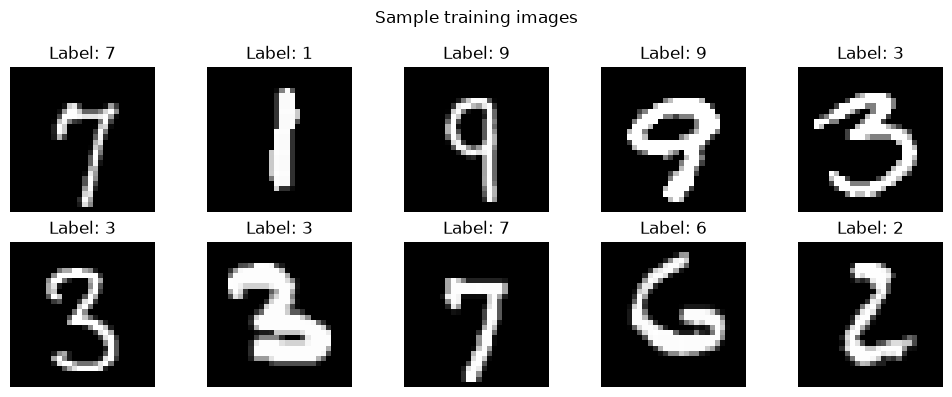

In [5]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample training images")
plt.tight_layout()
plt.show()

The digits are white on a black background and centered. Some are written neatly, others are slanted or thick, which is why a model that learns its own features is useful here.

## 2. Build a Fully Connected Neural Network

My model is a `Sequential` model, like in the course tutorial:
- an input layer for one 28×28 image, and a **Flatten** layer that turns it into a vector of 784 pixels,
- **two hidden layers** with ReLU activation (128 and 64 neurons),
- an **output layer** with 10 neurons and **softmax**, which gives one probability per digit.

I compile it with the Adam optimizer, **categorical cross-entropy** as the loss and **accuracy** as the metric. I put the model in a function because I reuse it in the tuning experiment.

In [6]:
def build_model(hidden1=128, hidden2=64, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),                 # input layer
        layers.Flatten(),                             # 28x28 -> 784
        layers.Dense(hidden1, activation="relu"),     # hidden layer 1
        layers.Dense(hidden2, activation="relu"),     # hidden layer 2
        layers.Dense(10, activation="softmax"),       # output layer: 10 probabilities
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

tf.keras.utils.set_random_seed(42)
model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

The model has 109,386 trainable parameters (weights and biases). Most of them are in the first hidden layer, because each of its 128 neurons is connected to all 784 pixels.

## 3. Train the Neural Network

I fit the model for **10 epochs** with batches of 32 images. After each epoch Keras checks the model on the validation set, so I can follow the loss and accuracy on images it does not train on.

In [7]:
history = model.fit(x_train, y_train_oh,
                    epochs=10, batch_size=32,
                    validation_data=(x_val, y_val_oh),
                    verbose=2)

Epoch 1/10


1563/1563 - 3s - 2ms/step - accuracy: 0.9221 - loss: 0.2635 - val_accuracy: 0.9524 - val_loss: 0.1577


Epoch 2/10


1563/1563 - 2s - 1ms/step - accuracy: 0.9653 - loss: 0.1125 - val_accuracy: 0.9660 - val_loss: 0.1124


Epoch 3/10


1563/1563 - 2s - 1ms/step - accuracy: 0.9770 - loss: 0.0743 - val_accuracy: 0.9682 - val_loss: 0.1074


... (10 outputs left out)

Epoch 9/10


1563/1563 - 2s - 1ms/step - accuracy: 0.9933 - loss: 0.0205 - val_accuracy: 0.9737 - val_loss: 0.1284


Epoch 10/10


1563/1563 - 2s - 1ms/step - accuracy: 0.9937 - loss: 0.0192 - val_accuracy: 0.9740 - val_loss: 0.1281


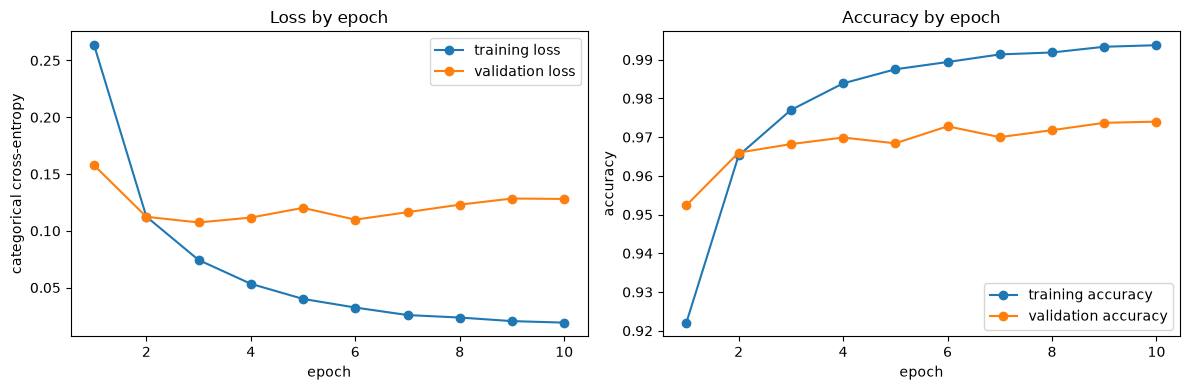

Lowest validation loss: 0.1074 at epoch 3
Final training accuracy: 0.9937 | final validation accuracy: 0.9740


In [8]:
hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, hist["loss"], marker="o", label="training loss")
plt.plot(epochs_range, hist["val_loss"], marker="o", label="validation loss")
plt.title("Loss by epoch"); plt.xlabel("epoch"); plt.ylabel("categorical cross-entropy"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, hist["accuracy"], marker="o", label="training accuracy")
plt.plot(epochs_range, hist["val_accuracy"], marker="o", label="validation accuracy")
plt.title("Accuracy by epoch"); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend()
plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(hist["val_loss"])) + 1
print(f"Lowest validation loss: {min(hist['val_loss']):.4f} at epoch {best_epoch}")
print(f"Final training accuracy: {hist['accuracy'][-1]:.4f} | final validation accuracy: {hist['val_accuracy'][-1]:.4f}")

**What I observe:** - The **training loss** goes down at every epoch (from 0.2635 to 0.0192) and the training accuracy climbs to **0.9937**.
- The **validation accuracy** rises fast in the first epochs and then stays around 0.97 (0.9740 at epoch 10).
- The **validation loss** is lowest at **epoch 3 (0.1074)** and then slowly goes back up (0.1281 at epoch 10), while the training loss keeps falling. The gap between training and validation shows that after about 3 epochs the model starts to **overfit**: it memorizes the training images more than it learns patterns that generalize. Training fewer epochs (or adding dropout or early stopping) would help.

## 4. Evaluate the Model's Performance

### Accuracy on the test set
Now I evaluate the model once on the 10,000 test images it has never seen.

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.1235
Test accuracy: 0.9721


**My interpretation:** The model reaches a **test accuracy of 0.9721** (test loss 0.1235): it correctly recognizes about 97 out of 100 handwritten digits it has never seen. This is very close to the final validation accuracy (0.9740), so the validation set gave me a good estimate. The test loss is higher than the lowest validation loss, which matches the overfitting I saw in the curves.

### Visualizing predictions on test images
I show some test images with the predicted and the true label (green = correct, red = wrong), and then some of the images the model got wrong.

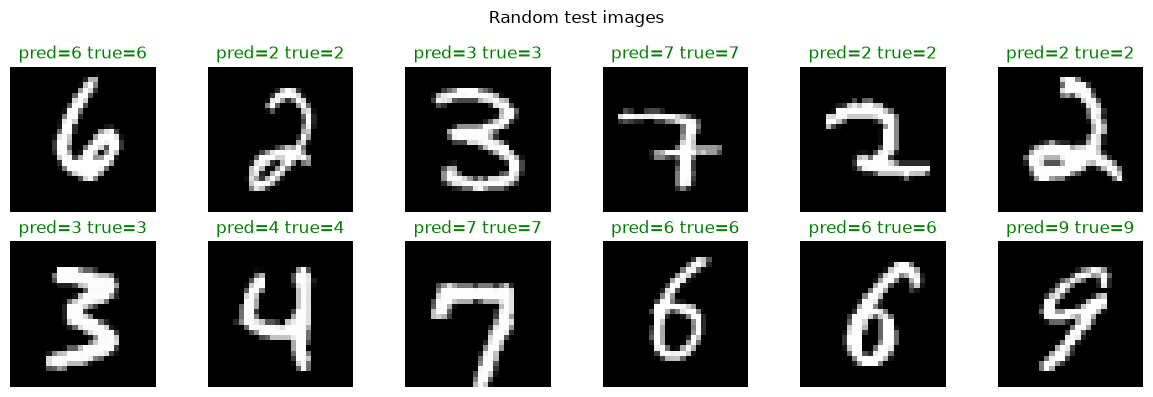

Number of misclassified test images: 279


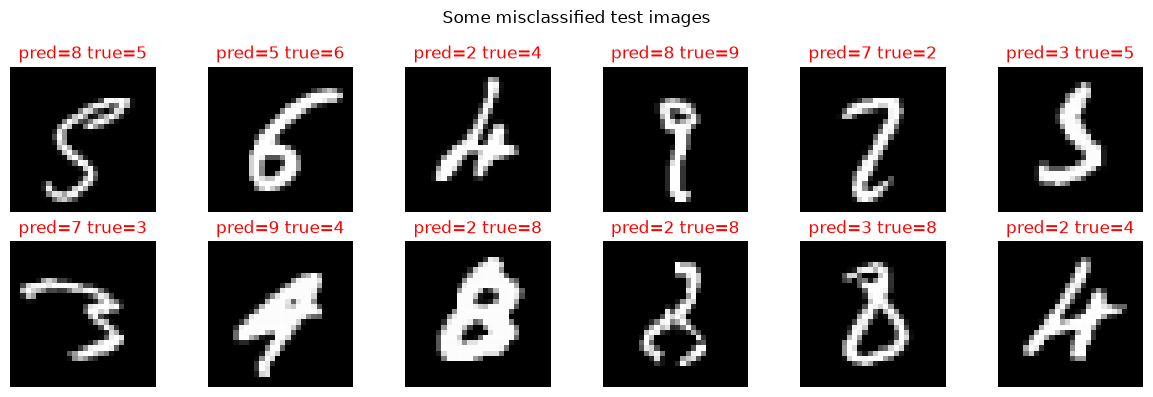

In [10]:
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

np.random.seed(42)
sample_idx = np.random.choice(len(x_test), size=12, replace=False)
plt.figure(figsize=(12, 4))
for i, k in enumerate(sample_idx, 1):
    plt.subplot(2, 6, i)
    plt.imshow(x_test[k], cmap="gray")
    color = "green" if y_pred[k] == y_test[k] else "red"
    plt.title(f"pred={y_pred[k]} true={y_test[k]}", color=color)
    plt.axis("off")
plt.suptitle("Random test images")
plt.tight_layout()
plt.show()

wrong_idx = np.where(y_pred != y_test)[0]
print("Number of misclassified test images:", len(wrong_idx))
plt.figure(figsize=(12, 4))
for i, k in enumerate(wrong_idx[:12], 1):
    plt.subplot(2, 6, i)
    plt.imshow(x_test[k], cmap="gray")
    plt.title(f"pred={y_pred[k]} true={y_test[k]}", color="red")
    plt.axis("off")
plt.suptitle("Some misclassified test images")
plt.tight_layout()
plt.show()

All 12 random test images are predicted correctly. Out of 10,000 test images, **279 are misclassified** (which matches the 0.9721 accuracy). Looking at the mistakes, many of them are digits that are hard to read even for me: a 5 with a loop that looks like an 8, a 4 written with an unusual cross stroke, an 8 that is thick or open, or a 3 with a long top stroke that looks like a 7.

### Confusion matrix
The confusion matrix shows, for each true digit (rows), how many test images were predicted as each digit (columns). The diagonal holds the correct predictions and everything outside it is a mistake.

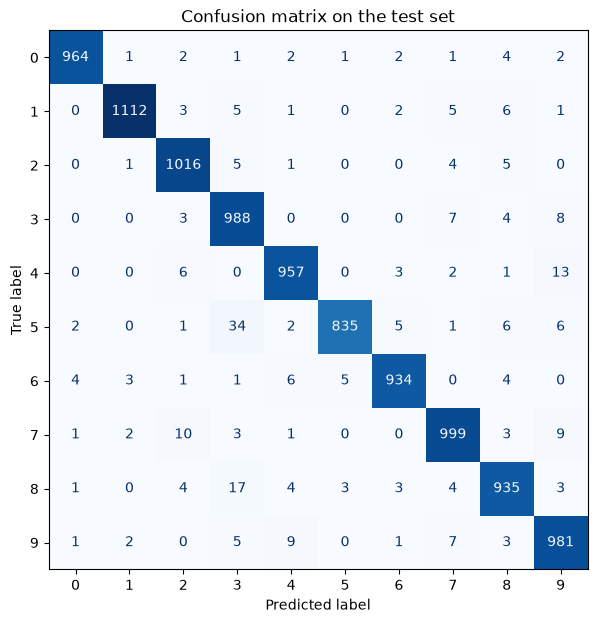

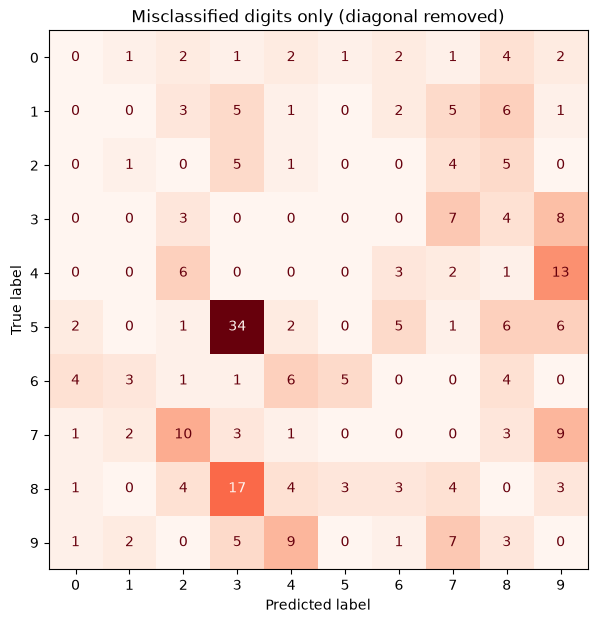

In [11]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix on the test set")
plt.show()

# Same matrix with the diagonal removed, to show only the misclassified digits
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm_errors, display_labels=range(10)).plot(ax=ax, cmap="Reds", colorbar=False)
ax.set_title("Misclassified digits only (diagonal removed)")
plt.show()

### Which digits does the model struggle with the most?
I calculate the accuracy for each digit and list the most frequent mistakes (true digit → predicted digit).

In [12]:
per_digit = pd.DataFrame({
    "digit": range(10),
    "test images": cm.sum(axis=1),
    "correct": np.diag(cm),
    "errors": cm.sum(axis=1) - np.diag(cm),
})
per_digit["accuracy"] = (per_digit["correct"] / per_digit["test images"]).round(4)
print(per_digit.sort_values("accuracy").to_string(index=False))

pairs = [(cm_errors[i, j], i, j) for i in range(10) for j in range(10) if cm_errors[i, j] > 0]
pairs.sort(reverse=True)
print("\nMost frequent mistakes:")
for count, true_digit, pred_digit in pairs[:5]:
    print(f"  true {true_digit} predicted as {pred_digit}: {count} times")

 digit  test images  correct  errors  accuracy
     5          892      835      57    0.9361
     8          974      935      39    0.9600
     7         1028      999      29    0.9718
     9         1009      981      28    0.9722
     4          982      957      25    0.9745
     6          958      934      24    0.9749
     3         1010      988      22    0.9782
     1         1135     1112      23    0.9797
     0          980      964      16    0.9837
     2         1032     1016      16    0.9845

Most frequent mistakes:
  true 5 predicted as 3: 34 times
  true 8 predicted as 3: 17 times
  true 4 predicted as 9: 13 times
  true 7 predicted as 2: 10 times
  true 9 predicted as 4: 9 times


**My interpretation:** - The digit the model struggles with **the most is 5**: only 835 of 892 test images are correct (accuracy **0.9361**, 57 errors). Its most common mistake is **5 predicted as 3 (34 times)**, the most frequent confusion in the whole matrix. A 5 and a 3 share the same curved bottom part.
- The second hardest digit is **8** (accuracy **0.9600**, 39 errors), most often predicted as 3 (17 times).
- Other frequent confusions are 4 → 9 (13 times), 7 → 2 (10 times) and 9 → 4 (9 times): these digits have similar shapes, like the closed or open top of a 4 and a 9.
- The easiest digits are **2** (0.9845) and **0** (0.9837).

My network only sees a flat vector of 784 pixels, so it does not really understand shapes and positions. A convolutional neural network (CNN), which looks at local patterns like edges and curves, would probably reduce these confusions.

## 5. A Basic Hyperparameter Tuning Experiment

To see how the settings change the result, I train the same kind of network with different **hidden layer sizes** and **learning rates**. To keep it fast, every run trains for 5 epochs with the same seed. I compare the runs on the **validation** accuracy (not the test set), so the test set stays a fair final check.

In [13]:
settings = [
    {"hidden1": 64,  "hidden2": 32,  "learning_rate": 0.001},
    {"hidden1": 128, "hidden2": 64,  "learning_rate": 0.001},
    {"hidden1": 256, "hidden2": 128, "learning_rate": 0.001},
    {"hidden1": 128, "hidden2": 64,  "learning_rate": 0.01},
    {"hidden1": 128, "hidden2": 64,  "learning_rate": 0.0001},
]

rows = []
for s in settings:
    tf.keras.utils.set_random_seed(42)
    m = build_model(**s)
    h = m.fit(x_train, y_train_oh, epochs=5, batch_size=32,
              validation_data=(x_val, y_val_oh), verbose=0)
    rows.append({**s,
                 "parameters": m.count_params(),
                 "train accuracy": round(h.history["accuracy"][-1], 4),
                 "validation accuracy": round(h.history["val_accuracy"][-1], 4),
                 "validation loss": round(h.history["val_loss"][-1], 4)})
    print("done:", s)

tuning = pd.DataFrame(rows).sort_values("validation accuracy", ascending=False)
tuning

done: {'hidden1': 64, 'hidden2': 32, 'learning_rate': 0.001}


done: {'hidden1': 128, 'hidden2': 64, 'learning_rate': 0.001}


done: {'hidden1': 256, 'hidden2': 128, 'learning_rate': 0.001}


done: {'hidden1': 128, 'hidden2': 64, 'learning_rate': 0.01}


done: {'hidden1': 128, 'hidden2': 64, 'learning_rate': 0.0001}


,hidden1,hidden2,learning_rate,parameters,train accuracy,validation accuracy,validation loss
2,256,128,0.0010,235146,0.9887,0.9744,0.1035
0,64,32,0.0010,52650,0.9816,0.9704,0.1102
1,128,64,0.0010,109386,0.9875,0.9684,0.1202
3,128,64,0.0100,109386,0.9642,0.9580,0.1877
4,128,64,0.0001,109386,0.9547,0.9530,0.1681


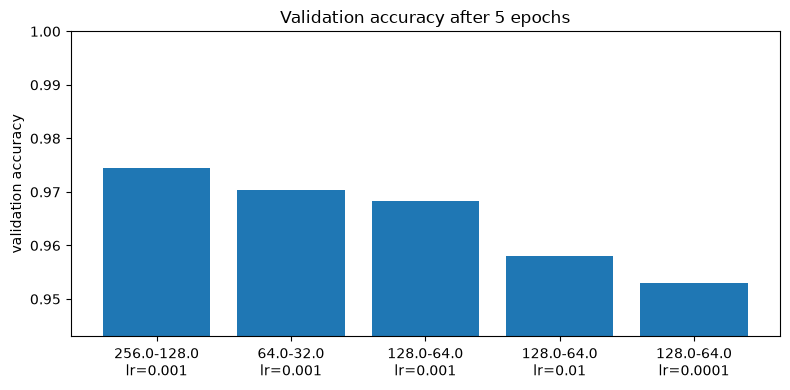

In [14]:
labels = [f"{r['hidden1']}-{r['hidden2']}\nlr={r['learning_rate']}" for _, r in tuning.iterrows()]
plt.figure(figsize=(8, 4))
plt.bar(labels, tuning["validation accuracy"])
plt.ylim(tuning["validation accuracy"].min() - 0.01, 1.0)
plt.title("Validation accuracy after 5 epochs")
plt.ylabel("validation accuracy")
plt.tight_layout()
plt.show()

**My interpretation:** - The **best setting is 256-128 neurons with learning rate 0.001**, with a validation accuracy of **0.9744** after 5 epochs (and the lowest validation loss, 0.1035). The bigger network has more parameters (235,146) to learn the digit shapes.
- Between the three layer sizes the differences are small (0.9684 to 0.9744). The 64-32 network (0.9704) even did a bit better than 128-64 (0.9684), so with one run per setting I cannot say that size alone explains these small gaps.
- The **learning rate matters more**: with **0.01** the steps are too big and the validation accuracy drops to 0.9580, and with **0.0001** the steps are too small, so after 5 epochs the model is still learning (0.9530). The default Adam learning rate of 0.001 works best here.

To go further, I would retrain the best setting, stop at the epoch with the lowest validation loss, and only then check it once on the test set.

## Conclusion

- I loaded MNIST with Keras, normalized the pixels to [0, 1], one-hot encoded the labels and split the data into 50,000 training, 10,000 validation and 10,000 test images.
- My fully connected network (Flatten → 128 ReLU → 64 ReLU → 10 softmax) trained for 10 epochs reached a **test accuracy of 0.9721**.
- The loss curves showed overfitting after about 3 epochs: the training loss kept falling while the validation loss went up.
- The confusion matrix showed that the hardest digit is **5** (often confused with 3), followed by **8**.
- In my tuning experiment the biggest network (256-128) with learning rate 0.001 was best (validation accuracy 0.9744), and a learning rate that is too high (0.01) or too low (0.0001) hurt the results.